# 02 · Domain classification experiments

Four model families trained on the same stratified 70/15/15 split (seed 42), tuned on the
validation split only. The test split was used once, after all choices were frozen, for the
best model (fine-tuned SciBERT) and for the model the API serves (MiniLM embeddings + Logistic
Regression, small enough for the free 512 MB backend). Produced by
`python -m src.pipeline.train_classifier`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
rep = json.loads(Path("reports/classification.json").read_text())
cmp = pd.read_csv("reports/model_comparison.csv")

## Model comparison (validation split)

In [2]:
cmp[["model", "val_accuracy", "val_f1_macro", "train_seconds"]]

,model,val_accuracy,val_f1_macro,train_seconds
0,Fine-tuned SciBERT,0.9500,0.9500,1003.9
1,SPECTER2 embeddings + Logistic Regression,0.9367,0.9368,3.8
2,TF-IDF + Linear SVM,0.9318,0.9319,7.6
3,MiniLM embeddings + Logistic Regression,0.9313,0.9314,13.1
4,TF-IDF + Logistic Regression,0.9278,0.9279,15.4
5,TF-IDF + Naive Bayes,0.9053,0.9051,9.8


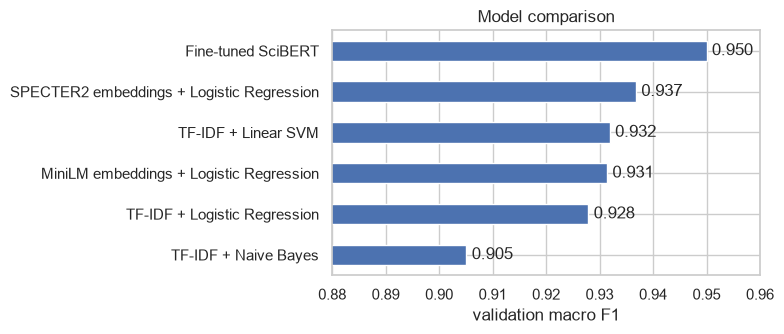

In [3]:
ax = cmp.set_index("model")["val_f1_macro"].sort_values().plot.barh(figsize=(8, 3.5), xlim=(0.88, 0.96), color="#4C72B0")
for i, v in enumerate(cmp.set_index("model")["val_f1_macro"].sort_values()):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center")
ax.set_xlabel("validation macro F1"); ax.set_ylabel(""); ax.set_title("Model comparison")
plt.tight_layout(); plt.savefig("reports/figures/model_comparison.png", dpi=150); plt.show()

## Test results (used once)

In [4]:
pd.DataFrame({name: {"roles": ", ".join(r["roles"]), **r["test"]} for name, r in rep["test"].items()}).T

,roles,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
Fine-tuned SciBERT,best_model,0.9538,0.9537,0.9538,0.9537,0.9537,0.9538,0.9537
MiniLM embeddings + Logistic Regression,served_model,0.9229,0.9227,0.9229,0.9228,0.9227,0.9229,0.9228


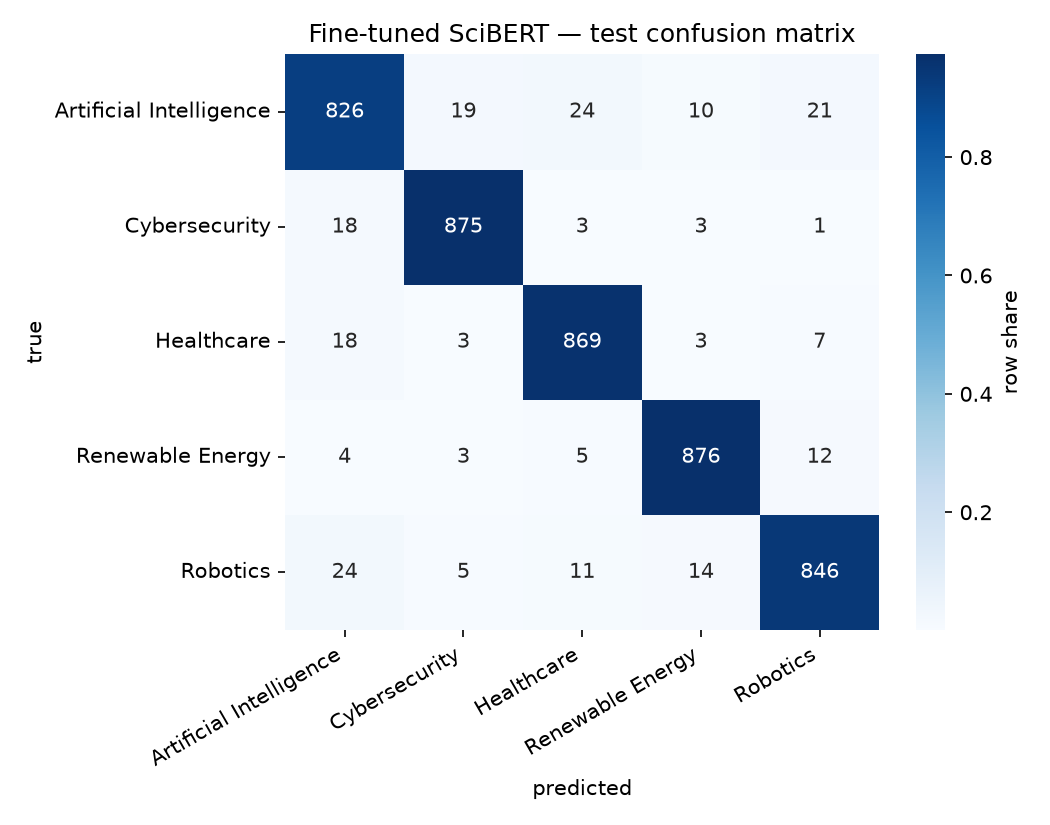

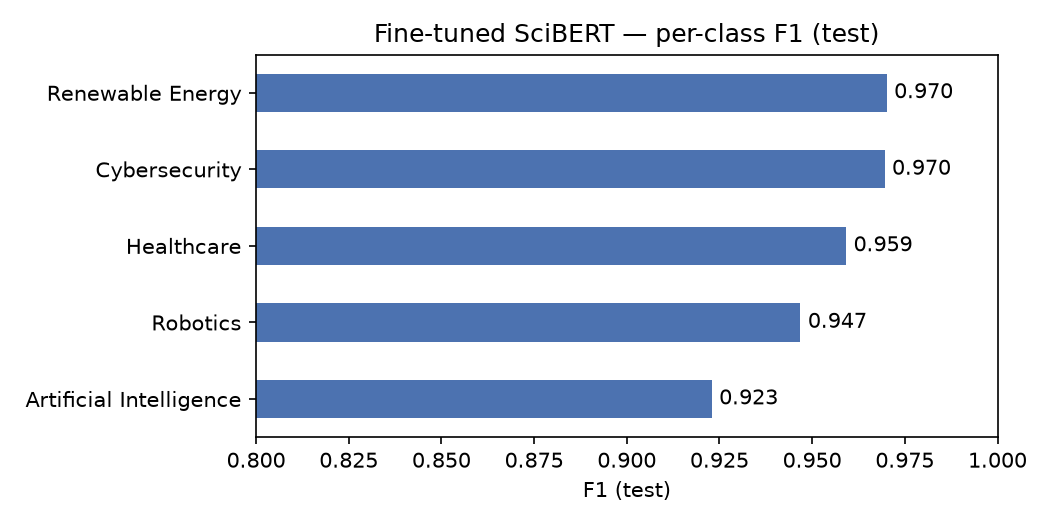

In [5]:
display(Image("reports/confusion_matrix.png")); display(Image("reports/per_class_f1.png"))

## Leakage check
The model input is only title + abstract. No CPC code or OpenAlex topic ID appears in any text.

In [6]:
pd.Series(rep["leakage_check"])

model_input                            text = title + '. ' + abstract (no other columns)
docs_with_cpc_code_in_text                                                             0
docs_with_openalex_topic_id_in_text                                                    0
note                                   domain, raw_codes and topic names are never pa...
dtype: object

## Embedding choice: SPECTER2 vs MiniLM
SPECTER2 + Logistic Regression is slightly better for classification, while MiniLM is better for
similarity retrieval (notebook 03) and is the only one that runs under fastembed on the free
backend, so MiniLM is the production embedding.

In [7]:
sim = json.loads(Path("reports/similarity_eval.json").read_text())
pd.DataFrame({
    "classification val macro F1 (+ LogReg)": rep["embedding_comparison_val_f1_macro"],
    "retrieval MRR": {"minilm": sim["minilm"]["mrr"], "specter2": sim["specter2"]["mrr"]},
    "dimension": {"minilm": 384, "specter2": 768},
})

,classification val macro F1 (+ LogReg),retrieval MRR,dimension
minilm,0.9314,0.2079,384
specter2,0.9368,0.1993,768


## Error analysis
Most errors sit on domain boundaries: AI methods applied to medical data (AI ↔ Healthcare),
learning-based robot control (Robotics ↔ AI), ML for intrusion or malware detection
(AI ↔ Cybersecurity) and robots or control systems for energy plants (Robotics ↔ Renewable
Energy). These documents genuinely belong to two domains; the label follows the source's primary
code or topic.

In [8]:
pd.Series(rep["top_confusions_best_model"], name="test errors")

Artificial Intelligence -> Healthcare       24
Robotics -> Artificial Intelligence         24
Artificial Intelligence -> Robotics         21
Artificial Intelligence -> Cybersecurity    19
Healthcare -> Artificial Intelligence       18
Cybersecurity -> Artificial Intelligence    18
Robotics -> Renewable Energy                14
Renewable Energy -> Robotics                12
Name: test errors, dtype: int64

In [9]:
pd.set_option("display.max_colwidth", 110)
pd.read_csv("reports/misclassified_examples.csv")

,doc_id,source,domain,predicted,title
0,PAT-US-12106015-B2,patent,Renewable Energy,Robotics,Method and system for evaluating and simulating nuclear power plant based on model
1,PAP-W4292491255,paper,Healthcare,Artificial Intelligence,Unsupervised knowledge-transfer for learned image reconstruction*
2,PAT-US-11087464-B2,patent,Artificial Intelligence,Healthcare,System and method for motion-adjusted device guidance using vascular roadmaps
3,PAT-US-11441817-B2,patent,Renewable Energy,Artificial Intelligence,Photothermal trap
4,PAT-US-12158869-B2,patent,Artificial Intelligence,Healthcare,Method of obtaining and imputing missing data and measurement system using the same
5,PAP-W3203261424,paper,Robotics,Renewable Energy,Classification of emerging patterns in self-assembled two-dimensional magnetic lattices
6,PAT-US-11468370-B1,patent,Artificial Intelligence,Cybersecurity,Communication compression method based on model weight distribution in federated learning
7,PAT-US-11874640-B2,patent,Robotics,Artificial Intelligence,Wind power prediction method and system for optimizing deep transformer network
8,PAP-W4365516111,paper,Robotics,Artificial Intelligence,Co-evolution of Human and AI-Robots to Expand Science Frontiers
9,PAT-US-12005592-B2,patent,Robotics,Artificial Intelligence,Creating training data variability in machine learning for object labelling from images
